In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

In [2]:
# Data processing
%run Data_processing.py

In [3]:
baseline = 'ssp534-over'#'CurPol_OS_1.5C'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

In [4]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|█████████████████████████████████████| 165/165 [00:00<00:00, 115208.95it/s]


# $\Delta T_p \times \Delta T_s$

## Running simulations

In [147]:
T_peaks = np.arange(0,5.1,step=0.05) # change step to 0.2 for faster
T_oss = np.arange(0,3.1,step=0.05)

years = np.arange(2015,2301)
no_years=len(years)

D = np.zeros((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
# D[:,:,]
temps = np.ones((len(T_peaks), len(T_oss), no_years))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(T_peaks.shape[0])):
    for j in range(T_oss.shape[0]): # T_os can only be less than T_peak
        # if T_oss[j] <= T_peaks[i]:
        PAR[1:3] = [T_peaks[i], T_oss[j]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)
                # D[i,j,t,:] = environmental_update(D[i,j,r,t-1,:], 
                #                                     A[r], 
                #                                     pc = pcs[i,j,t,:],
                #                                     pr = prs[i,j,t,:])

100%|███████████████████████████████████████| 102/102 [1:21:01<00:00, 47.66s/it]


In [148]:
D_nr = np.delete(D,6,axis=-1)
T = k_risk(D_nr[:,:,-1,:],1,axis=2)

In [149]:
reef_grad = np.gradient(D[:,:,-1,6], T_peaks, T_oss)
T_grad = np.gradient(T, T_peaks, T_oss)

In [150]:
data_folder = '../../../Data/Simulations/Overshoots/ssp534-over/TAT'
np.savetxt(data_folder+'/reef_mean.csv',D[:,:,-1,6])
np.savetxt(data_folder+'/T_mean.csv',T)

## Plotting

In [3]:
T_peaks = np.arange(0,5.1,step=0.05) # change step to 0.2 for faster
T_oss = np.arange(0,3.1,step=0.05)

data_folder = '../../../Data/Simulations/Overshoots/ssp534-over/TAT'
T = np.loadtxt(data_folder+'/T_mean.csv')
T_grad = np.gradient(T,T_peaks,T_oss)
popt = np.loadtxt('../../../Data/Simulations/Overshoots/ssp534-over/Baseline/popt.txt')

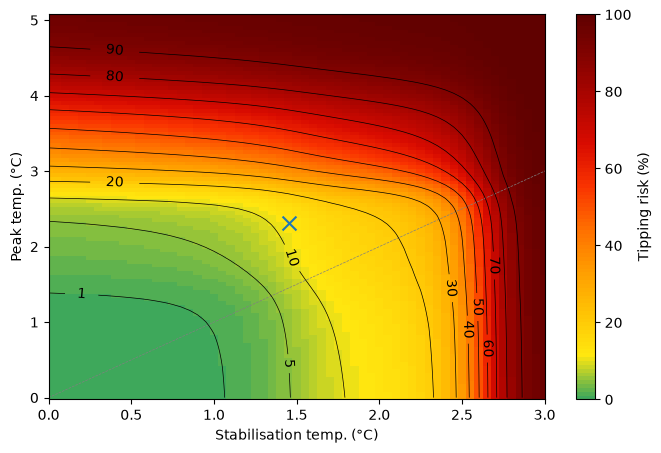

In [185]:
T_Pg,T_Og = np.meshgrid(T_peaks,T_oss,indexing='ij')
fig,ax = plt.subplots(figsize=(8,5))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100).with_extremes(bad='white')

to_plot = T

ax.plot([0,5],[0,5],ls='--',c='gray',lw=0.5)
ax.scatter(popt[2],popt[1],marker='x',s=100)
# im=ax.imshow(to_plot*100,cmap=cmap,#cmap='Reds',
#               extent=(T_peaks[0], T_peaks[-1], T_oss[0], T_oss[-1]),
#               origin='lower',vmin=0,vmax=100,zorder=0)
im=ax.imshow(to_plot*100,cmap=cmap,#cmap='Reds',
              extent=(T_oss[0] - np.diff(T_oss)[0]/2, 
                      T_oss[-1]+ np.diff(T_oss)[0]/2,
                      T_peaks[0] - np.diff(T_peaks)[0]/2, 
                      T_peaks[-1]+ np.diff(T_peaks)[0]/2),
              origin='lower',vmin=0,vmax=100,zorder=0,aspect='auto')
fig.colorbar(im,ax=ax,label='Tipping risk (%)')
CS = ax.contour(T_Og,T_Pg, to_plot*100,[1,5]+[i for i in range(10,100,10)],
                 corner_mask=True,colors=['k'],linewidths=0.5)
ax.clabel(CS)
# plt.clabel(CS)
ax.set_ylabel('Peak temp. (°C)')
ax.set_xlabel('Stabilisation temp. (°C)')

ax.set_xlim(0,3)
# ax.set_title('Aggregate risk heatmap for %s scenario'%baseline)
# plt.colorbar(im)

fig.savefig('../../../Figures/Overshoots/Submission/2d_ssp534-over_TpTs.pdf',bbox_inches='tight',dpi=300,format='pdf')

## gradients

In [60]:
def symlog(x):
    """ Returns the symmetric log10 value """
    return np.sign(x) * np.log10(np.abs(x))

def symexp(x):
    """ Returns the symmetric exponential value"""
    return np.sign(x) * np.exp(np.abs(x))

T_grad = np.gradient(T,[np.diff(T_peaks)[0],np.diff(T_peaks)[1]])

In [5]:
T_Pg,T_Og = np.meshgrid(T_peaks,T_oss,indexing='ij')
T_Pg.shape

(102, 62)

In [7]:
grad_angles = np.arctan(T_grad[0]/T_grad[1])

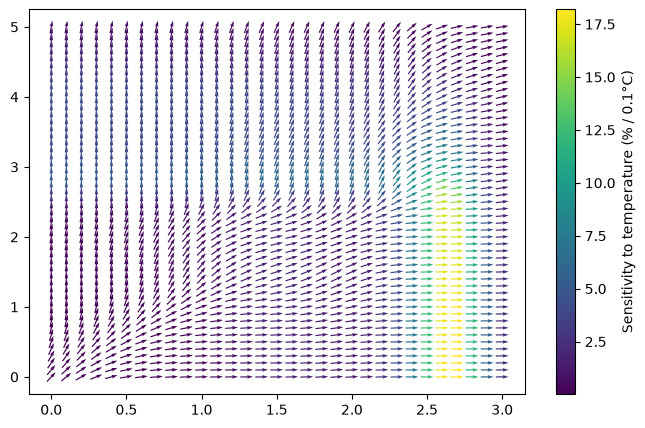

In [14]:
fig,ax = plt.subplots(figsize=(8,5))
im=ax.quiver(T_Og[::2,::2],T_Pg[::2,::2],
             np.cos(grad_angles)[::2,::2],np.sin(grad_angles)[::2,::2], 
             100*0.1*np.sqrt(T_grad[0]**2+T_grad[1]**2)[::2,::2],
             angles='uv',pivot='middle',
             units='height',scale=30,cmap='viridis',
             # norm=mpl.colors.LogNorm()
          )
          # scale_units="width",scale=60)
# CS = ax.contour(T_Og,T_Pg, to_plot.T*100,[10,30,50,70,90],
#                  corner_mask=True,colors=['k'],linewidths=0.5)
fig.colorbar(im,label='Sensitivity to temperature (% / 0.1°C)')
fig.savefig('../../../Figures/Overshoots/Submission/2d_peak_stab_grad_unit_arrows.png',bbox_inches='tight')

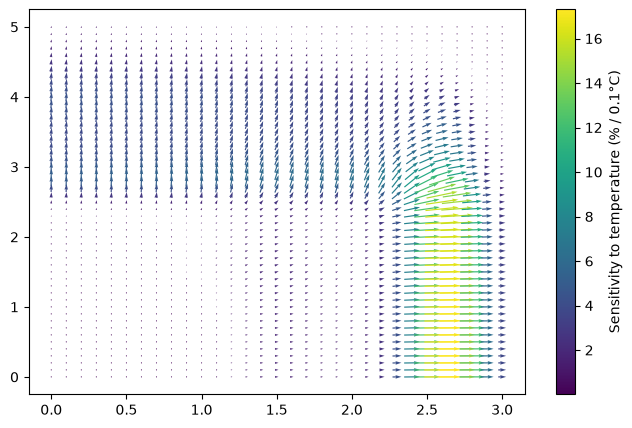

In [146]:
fig,ax = plt.subplots(figsize=(8,5))
im=ax.quiver(T_Og,T_Pg,
             100*0.1*T_grad[1],100*0.1*T_grad[0], 
             100*0.1*np.sqrt(T_grad[0]**2+T_grad[1]**2),
             angles='uv',pivot='middle',
             units='height',cmap='viridis'
          )
          # scale_units="width",scale=60)
# CS = ax.contour(T_Og,T_Pg, to_plot.T*100,[10,30,50,70,90],
#                  corner_mask=True,colors=['k'],linewidths=0.5)
fig.colorbar(im,label='Sensitivity to temperature (% / 0.1°C)')

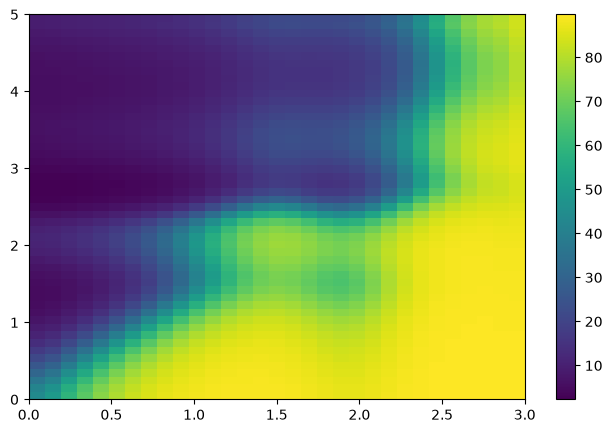

In [117]:
fig,ax=plt.subplots(figsize=(8,5))
im=ax.imshow(np.rad2deg(grad_angles),origin='lower',
             extent=(T_oss[0] - np.diff(T_oss)[0]/2, 
                     T_oss[-1]+ np.diff(T_oss)[0]/2,
                     T_peaks[0] - np.diff(T_peaks)[0]/2, 
                     T_peaks[-1]+ np.diff(T_peaks)[0]/2),aspect='auto')
# im=ax.imshow(np.log(np.sqrt(T_grad[0]**2+T_grad[1]**2))+7,origin='lower',
#               extent=(T_oss[0], T_oss[-1],T_peaks[0], T_peaks[-1]),aspect='auto')
fig.colorbar(im,ax=ax)

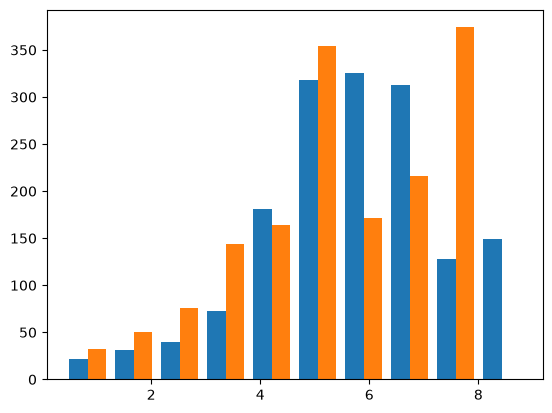

In [109]:
plt.hist([np.log(100*0.1*T_grad[1].flatten())+6,np.log(100*0.1*T_grad[0].flatten())+6]);

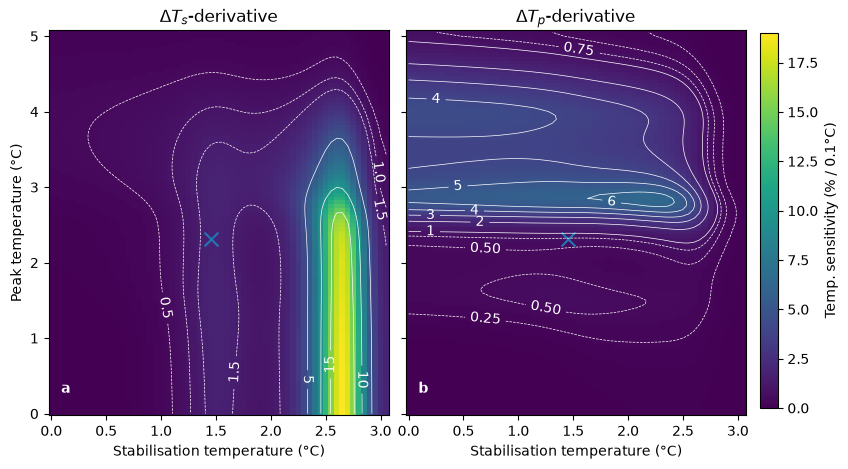

In [392]:
T_Pg,T_Og = np.meshgrid(T_peaks,T_oss,indexing='ij')
T_Pg.shape

fig,axs=plt.subplots(figsize=(9,5),ncols=2,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.0,wspace=0.05)
cmap = 'viridis'
scale = 100*0.1
# cbar_labels = ['Sensitivity to %s'%s for s in ['stabilisation (% / 0.1°C)','peak (% / 0.1°C)']]
risk_contours = [np.arange(0,20,5), np.arange(7)]
risk_contours_dots = [np.arange(0, 2, 0.5), np.arange(0,1,0.25)]
colors=['k','w']
titles=[r'$\Delta T_s$-derivative',r'$\Delta T_p$-derivative']
# axs[0].set_xlim(0,200)
# axs[0].set_ylim(0,3)
for i,ax,cbar_lab in zip(range(2),axs,cbar_labels):
    im = ax.imshow(T_grad[1-i]*scale,origin='lower',
                   extent=(T_oss[0] - np.diff(T_oss)[0]/2, 
                           T_oss[-1]+ np.diff(T_oss)[0]/2,
                           T_peaks[0] - np.diff(T_peaks)[0]/2, 
                           T_peaks[-1]+ np.diff(T_peaks)[0]/2),
                   aspect='auto',
                   cmap=cmap,vmin=0,vmax=19)
    ax.scatter(popt[2],popt[1],marker='x',s=100)
    cs = ax.contour(T_Og,T_Pg,T_grad[1-i]*scale,
                    risk_contours[i],
                    corner_mask=True,
                    colors=['w'],linewidths=0.5)
    cs2 = ax.contour(T_Og,T_Pg,T_grad[1-i]*scale,
                    risk_contours_dots[i],
                    corner_mask=True,
                    colors=['w'],linewidths=0.5,ls='--')
    ax.clabel(cs)
    ax.clabel(cs2)
    leg = axs[i].legend(handles=[],title='ab'[i],
                    loc='lower left',
                    title_fontproperties={'weight':'bold'},frameon=False)
    plt.setp(leg.get_title(), color='white')
    axs[i].set_xlabel('Stabilisation temperature (°C)')
    axs[i].set_title(titles[i])

cax=fig.add_axes((0.915,0.125,0.02,0.75))
fig.colorbar(im,cax=cax,label='Temp. sensitivity (% / 0.1°C)')

# axs[1].set_xlabel('Stabilisation temperature (°C)')
# fig.supxlabel('Stabilisation temperature (°C)')
# fig.supylabel('Peak temperature (°C)',x=0.05)

axs[0].set_ylabel('Peak temperature (°C)')

fig.savefig('../../../Figures/Overshoots/Submission/2d_ssp534-over_TpTs_grads.pdf',bbox_inches='tight',dpi=300,format='pdf')

In [336]:
T_grad[0][round(46), round(29)]*scale

np.float64(0.677352033510914)

In [333]:
for i,temp_name in enumerate(['peak','stab']):
    print(temp_name,T_grad[i][round(popt[1]*20), round(popt[2]*20)]*scale)

peak 0.677352033510914
stab 1.7386970516733102


In [325]:
print(T_grad[0].min()*scale,T_grad[0].max()*scale)
print(T_grad[1].min()*scale,T_grad[1].max()*scale)

0.001747356859871349 6.461519898848516
0.004129879612668752 18.950102253009113


In [82]:
np.sqrt(T_grad[0]**2+T_grad[1]**2).max()

np.float64(1.7310286583521926)

# $\Delta T_s \times t_d$

In [163]:
T_oss = np.arange(0,3.01,step=0.05)
t_downs = np.arange(0,201,step=5)

years = np.arange(2015,2301)
no_years=len(years)

D = np.zeros((len(t_downs), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
temps = np.ones((D.shape[:-1]))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(t_downs.shape[0])):
    for j in range(T_oss.shape[0]): # T_os can only be less than T_peak
        # if T_oss[j] <= T_peaks[i]:
        PAR[[2,-1]] = [T_oss[j],t_downs[i]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)

100%|███████████████████████████████████████████| 41/41 [32:53<00:00, 48.14s/it]


In [164]:
D_nr = np.delete(D,6,axis=-1)
T = k_risk(D_nr[:,:,-1,:],1,axis=2)

data_folder = '../../../Data/Simulations/Overshoots/ssp534-over/TAT'
np.savetxt(data_folder+'/reef_mean_stab_down.csv',D[:,:,-1,6])
np.savetxt(data_folder+'/T_mean_stab_down.csv',T)

In [393]:
T_oss = np.arange(0,3.01,step=0.05)
t_downs = np.arange(0,201,step=5)

data_folder = '../../../Data/Simulations/Overshoots/ssp534-over/TAT'
T = np.loadtxt(data_folder+'/T_mean_stab_down.csv')
T_grad = np.gradient(T,t_downs,T_oss)

popt = np.loadtxt('../../../Data/Simulations/Overshoots/ssp534-over/Baseline/popt.txt')

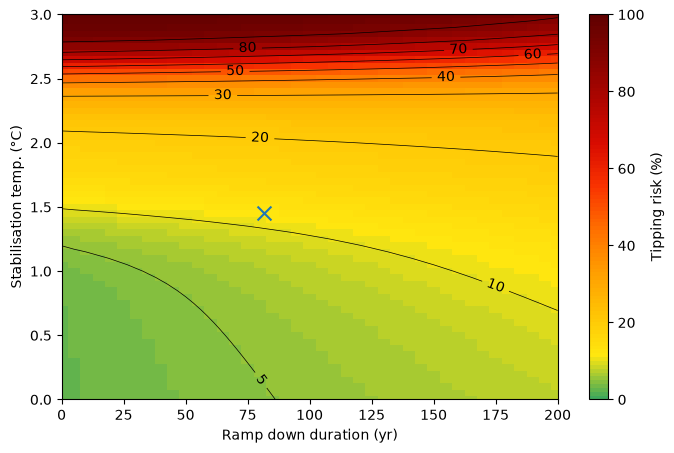

In [304]:
T_Sg,t_Dg = np.meshgrid(T_oss,t_downs)
fig,ax = plt.subplots(figsize=(8,5))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100).with_extremes(bad='white')

to_plot = T.T
ax.scatter(popt[-1],popt[2],marker='x',s=100)
im=ax.imshow(to_plot*100,cmap=cmap,#cmap='Reds',
              extent=(t_downs[0]  - np.diff(t_downs)[0]/2, 
                      t_downs[-1] + np.diff(t_downs)[0]/2, 
                      T_oss[0] - np.diff(T_oss)[0]/2, 
                      T_oss[-1]+ np.diff(T_oss)[0]/2),
              origin='lower',vmin=0,vmax=100,zorder=0,aspect='auto')
fig.colorbar(im,ax=ax,label='Tipping risk (%)')
CS = ax.contour(t_Dg,T_Sg, to_plot.T*100,[1,5]+[i for i in range(10,100,10)],
                 corner_mask=True,colors=['k'],linewidths=0.5)
ax.clabel(CS,CS.levels[:10])
ax.set_xlabel('Ramp down duration (yr)')
ax.set_ylabel('Stabilisation temp. (°C)')
ax.set_xlim(0,200)
ax.set_ylim(0,3)
# ax.set_title('Aggregate risk heatmap for %s scenario'%baseline)

fig.savefig('../../../Figures/Overshoots/Submission/2d_ssp534-over_Tstd.pdf',bbox_inches='tight',dpi=300,format='pdf')

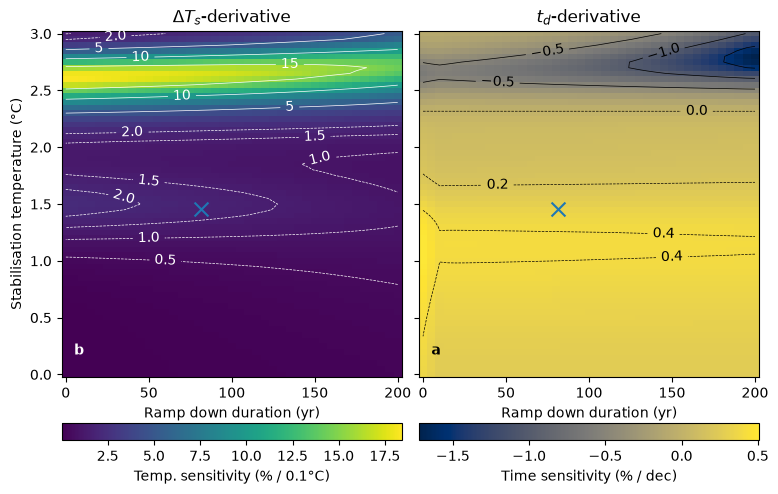

In [438]:
fig,axs=plt.subplots(figsize=(9,6),ncols=2,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.00,wspace=0.05)
cmaps = ['cividis','viridis']
scales = [100*10,100*0.1]
cbar_labels = ['%s sensitivity %s'%(s,unit) for s,unit in zip(['Time','Temp.'], ['(% / dec)','(% / 0.1°C)'])]
risk_contours = [np.arange(-1.5,-.05,0.5), np.arange(0,20,5)]
risk_contours_dot = [np.arange(0,0.6,0.2), np.arange(0,2.5,0.5)]

colors=['k','w']
titles=[r'$t_d$-derivative',r'$\Delta T_s$-derivative']
ims = []
for i,ax,scale,cbar_lab,cmap,l in zip(range(2),axs[::-1],scales,cbar_labels,cmaps,'ab'):
    im = ax.imshow(T_grad[i].T*scale,origin='lower',
                   extent=(t_downs[0]  - np.diff(t_downs)[0]/2, 
                           t_downs[-1] + np.diff(t_downs)[0]/2, 
                           T_oss[0] - np.diff(T_oss)[0]/2, 
                           T_oss[-1]+ np.diff(T_oss)[0]/2),
                   aspect='auto',cmap=cmap)
    ax.scatter(popt[-1],popt[2],marker='x',s=100)
    cs = ax.contour(t_Dg,T_Sg,T_grad[i]*scale,
                    risk_contours[i],
                    corner_mask=True,colors=[colors[i]],linewidths=0.5,ls='-')
    cs2 = ax.contour(t_Dg,T_Sg,T_grad[i]*scale,
                    risk_contours_dot[i],
                    corner_mask=True,colors=[colors[i]],linewidths=0.5,ls='--')
    ax.clabel(cs)
    ax.clabel(cs2)
    fig.colorbar(im,ax=ax,label=cbar_lab,orientation='horizontal',pad=0.1)
    ax.set_xlabel('Ramp down duration (yr)')
    ax.set_title(titles[i])

axs[1].legend(handles=[],title='a',
                loc='lower left',
                title_fontproperties={'weight':'bold'},frameon=False)
leg = axs[0].legend(handles=[],title='b',
                loc='lower left',
                title_fontproperties={'weight':'bold'},frameon=False)
plt.setp(leg.get_title(), color='white')

axs[0].set_ylabel('Stabilisation temperature (°C)')

fig.savefig('../../../Figures/Overshoots/Submission/2d_ssp534-over_Tstd_grads.pdf',bbox_inches='tight',dpi=300,format='pdf')